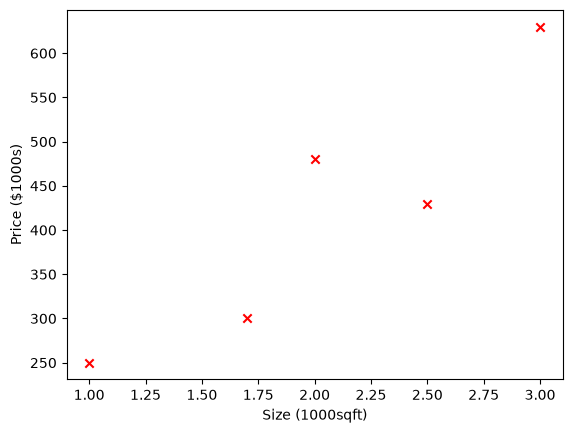

In [18]:
import numpy as np
import matplotlib.pyplot as plt
x=np.array([1.0,1.7,2.0,2.5,3.0])
y=np.array([250,300,480,430,630])
plt.scatter(x,y,marker='x',c='r')
plt.xlabel("Size (1000sqft)")
plt.ylabel("Price ($1000s)")
plt.savefig("plot.png")
plt.show()

In [5]:
def cost(x,y,w,b):
    return np.mean((w*x+b-y)**2)/2

In [6]:
print(cost(x,y,0,0))

96470.0


In [7]:
def gradient(x,y,w,b):
    err=w*x+b-y
    dw=np.mean(err*x)
    db=np.mean(err)
    return dw,db
    

In [8]:
print(gradient(x,y,0,0))

(np.float64(-937.0), np.float64(-418.0))


In [10]:
def train(x,y,lr,iters=1000):
    w,b=0.0,0.0 
    history=[]
    for _ in range(iters):
        dw,db=gradient(x,y,w,b)
        w=w-lr*dw
        b=b-lr*db
        history.append(cost(x,y,w,b))
    return w,b,history
w,b,history=train(x,y,lr=0.1,iters=1000)
print(w,b)
print(history[0],history[-1])


180.70071660464163 49.37101454130251
20380.509059999993 1493.1646671440003


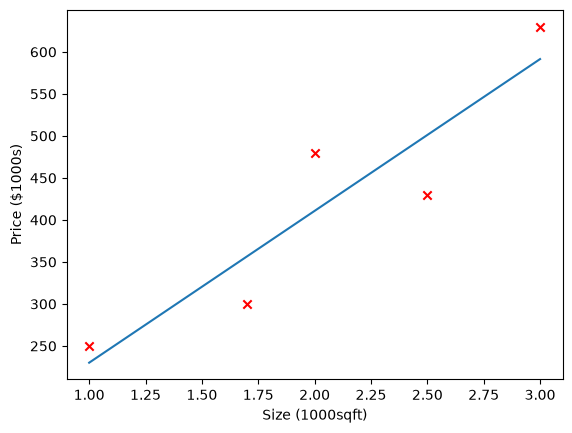

In [20]:
plt.scatter(x,y,marker='x',c='r')
plt.plot(x,w*x+b)
plt.xlabel("Size (1000sqft)")
plt.ylabel("Price ($1000s)")
plt.savefig("fitted-line.png")
plt.show()

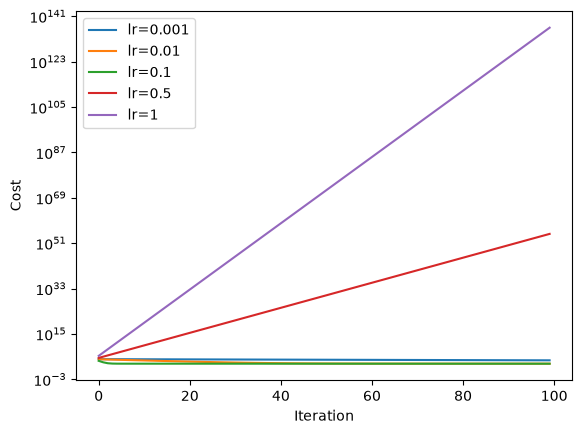

In [24]:
for lr in [0.001,0.01,0.1,0.5,1]:
    _,_,hist=train(x,y,lr=lr,iters=100)
    plt.plot(hist,label=f"lr={lr}")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.legend()
plt.savefig("lr-divergence.png")
plt.show()

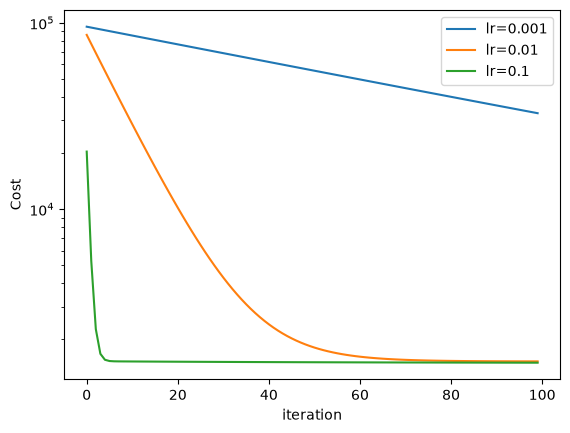

In [25]:
for lr in [0.001,0.01,0.1]:
  _w,_b,hist=train(x,y,lr=lr,iters=100)
  plt.plot(hist,label=f"lr={lr}")
plt.yscale("log")
plt.xlabel("iteration")
plt.ylabel("Cost")
plt.legend()
plt.savefig("lr-converging.png")
plt.show()


In [15]:
print(np.polyfit(x,y,1))
w,b,history=train(x,y,lr=0.1,iters=1000)
print(w,b)

[180.70325901  49.36535163]
180.70071660464163 49.37101454130251


In [17]:
def numerical_grad(x,y,w,b,eps=1e-5):
    dw=(cost(x,y,w+eps,b)-cost(x,y,w-eps,b))/(2*eps)
    db=(cost(x,y,w,b+eps)-cost(x,y,w,b-eps))/(2*eps)
    return dw,db
print(gradient(x,y,0.5,10))
print(numerical_grad(x,y,0.5,10))

(np.float64(-914.2860000000001), np.float64(-406.98))
(np.float64(-914.2860006249974), np.float64(-406.97999938856805))
